# **D.** Evaluate Algorithm

# Upload and prepare the dataset


In [23]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
uploaded = files.upload()
filename = next(iter(uploaded))

if filename.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(io.BytesIO(uploaded[filename]))
else:
    df = pd.read_csv(io.BytesIO(uploaded[filename]))

df.columns = df.columns.str.strip()
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].replace(r"^\\s*$", np.nan, regex=True)

if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

if "Churn" not in df.columns:
    raise ValueError("Dataset must contain a 'Churn' target column.")

df = df[df["Churn"].isin(["Yes", "No"])].drop_duplicates().copy()
y = df["Churn"].map({"No": 0, "Yes": 1})
X = df.drop(columns=["Churn"])
if "customerID" in X.columns:
    X = X.drop(columns=["customerID"])

print("Dataset shape after basic cleaning:", df.shape)
print("Predictor count:", X.shape[1])
print("Target distribution:")
display(y.value_counts().rename(index={0:"No Churn", 1:"Churn"}).to_frame("Customers"))


Saving WA_Fn-UseC_-Telco-Customer-Churn (1).csv to WA_Fn-UseC_-Telco-Customer-Churn (1) (1).csv
Dataset shape after basic cleaning: (7043, 21)
Predictor count: 19
Target distribution:


,Customers
Churn,
No Churn,5174
Churn,1869


D1.

D2. Candidate assumptions and whether the data satisfy them


D3. Validation scheme

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

def make_preprocessor(scale_numeric=False):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    numeric_pipe = Pipeline(steps=numeric_steps)
    categorical_pipe = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer(transformers=[
        ("num", numeric_pipe, numeric_features),
        ("cat", categorical_pipe, categorical_features)
    ])

models = {
    "Logistic Regression": Pipeline([
        ("prep", make_preprocessor(scale_numeric=True)),
        ("model", LogisticRegression(
            max_iter=2000, class_weight="balanced", random_state=42
        ))
    ]),
    "Random Forest": Pipeline([
        ("prep", make_preprocessor(scale_numeric=False)),
        ("model", RandomForestClassifier(
            n_estimators=300, class_weight="balanced",
            min_samples_leaf=2, random_state=42, n_jobs=-1
        ))
    ]),
    "KNN": Pipeline([
        ("prep", make_preprocessor(scale_numeric=True)),
        ("model", KNeighborsClassifier(n_neighbors=15, weights="distance"))
    ])
}

baseline = Pipeline([
    ("prep", make_preprocessor(scale_numeric=False)),
    ("model", DummyClassifier(strategy="most_frequent"))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "accuracy": "accuracy"
}

print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Training churn rate:", round(y_train.mean() * 100, 2), "%")
print("Test churn rate:", round(y_test.mean() * 100, 2), "%")


Training rows: 5634 | Test rows: 1409
Training churn rate: 26.54 %
Test churn rate: 26.54 %


D4. Compare candidates with the baseline

In [ ]:
all_models = {"Majority-Class Baseline": baseline, **models}
cv_rows = []
fold_recall = {}

for name, estimator in all_models.items():
    scores = cross_validate(
        estimator, X_train, y_train,
        cv=cv, scoring=scoring,
        return_train_score=False, n_jobs=-1
    )
    fold_recall[name] = scores["test_recall"]
    cv_rows.append({
        "Model": name,
        "Recall Mean": scores["test_recall"].mean(),
        "Recall SD": scores["test_recall"].std(),
        "F1 Mean": scores["test_f1"].mean(),
        "ROC-AUC Mean": scores["test_roc_auc"].mean(),
        "Accuracy Mean": scores["test_accuracy"].mean()
    })

cv_results = pd.DataFrame(cv_rows).sort_values(
    "Recall Mean", ascending=False
).reset_index(drop=True)

print("Cross-validation results (training set only):")
display(cv_results.round(4))

Cross-validation results (training set only):


,Model,Recall Mean,Recall SD,F1 Mean,ROC-AUC Mean,Accuracy Mean
0,Logistic Regression,0.8013,0.0379,0.6279,0.8459,0.7481
1,Random Forest,0.6408,0.0228,0.6155,0.8370,0.7875
2,KNN,0.5344,0.0162,0.5555,0.8049,0.7730
3,Majority-Class Baseline,0.0000,0.0000,0.0000,0.5000,0.7346


D5. Shortlist a model

In [ ]:
candidate_results = cv_results[
    cv_results["Model"] != "Majority-Class Baseline"
].copy()

shortlisted_name = candidate_results.iloc[0]["Model"]
shortlisted_model = models[shortlisted_name]

print("Shortlisted model:", shortlisted_name)
print("\\nShortlist comparison:")
display(candidate_results.round(4))

# Fit shortlisted model on the full training set only.
shortlisted_model.fit(X_train, y_train)
print("Shortlisted model fitted on training data.")


Shortlisted model: Logistic Regression
\nShortlist comparison:


,Model,Recall Mean,Recall SD,F1 Mean,ROC-AUC Mean,Accuracy Mean
0,Logistic Regression,0.8013,0.0379,0.6279,0.8459,0.7481
1,Random Forest,0.6408,0.0228,0.6155,0.8370,0.7875
2,KNN,0.5344,0.0162,0.5555,0.8049,0.7730


Shortlisted model fitted on training data.


D6. Error analysis: where does the shortlisted model fail?

Final test metrics for: Logistic Regression
Recall: 0.7834
F1-score: 0.6136
ROC-AUC: 0.8413
Accuracy: 0.7381
Precision: 0.5043
\nClassification report:
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



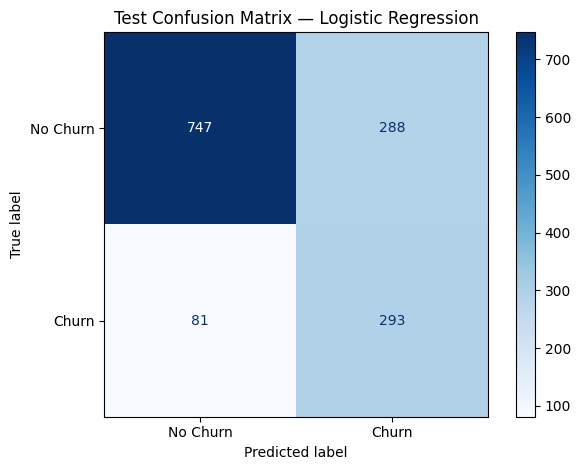

In [ ]:
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report, recall_score, f1_score,
    roc_auc_score, accuracy_score, precision_score
)

test_pred = shortlisted_model.predict(X_test)
test_prob = shortlisted_model.predict_proba(X_test)[:, 1]

print("Final test metrics for:", shortlisted_name)
print("Recall:", round(recall_score(y_test, test_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, test_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_prob), 4))
print("Accuracy:", round(accuracy_score(y_test, test_pred), 4))
print("Precision:", round(precision_score(y_test, test_pred, zero_division=0), 4))

print("\\nClassification report:")
print(classification_report(
    y_test, test_pred, target_names=["No Churn", "Churn"]
))

cm = confusion_matrix(y_test, test_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Test Confusion Matrix — {shortlisted_name}")
plt.tight_layout()
plt.show()


In [ ]:
error_analysis = X_test.copy()
error_analysis["Actual_Churn"] = y_test
error_analysis["Predicted_Churn"] = test_pred
error_analysis["Predicted_Churn_Probability"] = test_prob

false_negatives = error_analysis[
    (error_analysis["Actual_Churn"] == 1) &
    (error_analysis["Predicted_Churn"] == 0)
].sort_values("Predicted_Churn_Probability", ascending=False)

false_positives = error_analysis[
    (error_analysis["Actual_Churn"] == 0) &
    (error_analysis["Predicted_Churn"] == 1)
].sort_values("Predicted_Churn_Probability", ascending=False)

print("False negatives (missed churners):", len(false_negatives))
display(false_negatives.head(10))

print("False positives (unnecessary churn alerts):", len(false_positives))
display(false_positives.head(10))


False negatives (missed churners): 81


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Predicted_Churn,Predicted_Churn_Probability
3743,Male,0,No,Yes,4,Yes,No,DSL,Yes,No,...,No,No,Month-to-month,No,Electronic check,49.35,219.65,1,0,0.497288
4740,Male,1,Yes,No,24,No,No phone service,DSL,Yes,No,...,No,Yes,Month-to-month,No,Bank transfer (automatic),39.10,971.30,1,0,0.496897
2451,Male,0,Yes,Yes,28,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Yes,One year,No,Electronic check,106.10,2847.40,1,0,0.493601
1890,Female,0,Yes,Yes,1,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,Month-to-month,Yes,Electronic check,21.00,21.00,1,0,0.492233
5509,Female,0,No,Yes,5,Yes,No,DSL,No,No,...,No,No,Month-to-month,No,Mailed check,46.00,221.70,1,0,0.488339
5806,Female,0,No,Yes,2,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,Month-to-month,Yes,Electronic check,19.60,35.85,1,0,0.485310
223,Male,0,Yes,No,4,Yes,No,DSL,No,No,...,No,No,Month-to-month,No,Mailed check,50.05,179.35,1,0,0.483591
6796,Male,0,Yes,Yes,2,Yes,Yes,DSL,Yes,No,...,No,No,Month-to-month,No,Mailed check,56.70,113.55,1,0,0.479022
5585,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,Month-to-month,Yes,Mailed check,19.30,19.30,1,0,0.476878
3679,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,Month-to-month,Yes,Mailed check,20.10,20.10,1,0,0.472526


False positives (unnecessary churn alerts): 288


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Predicted_Churn,Predicted_Churn_Probability
3346,Female,1,No,No,2,Yes,Yes,Fiber optic,No,No,...,No,Yes,Month-to-month,Yes,Electronic check,84.05,186.05,0,1,0.920248
4039,Male,0,No,No,7,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,94.10,701.30,0,1,0.918097
935,Female,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,...,Yes,No,Month-to-month,Yes,Electronic check,83.25,308.05,0,1,0.915773
5019,Male,1,No,No,14,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,95.60,1273.30,0,1,0.911573
352,Female,1,No,No,7,Yes,No,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,89.15,574.35,0,1,0.906909
2519,Male,0,Yes,No,2,Yes,Yes,Fiber optic,No,No,...,Yes,No,Month-to-month,Yes,Electronic check,91.45,171.45,0,1,0.901260
2350,Female,0,No,No,5,Yes,Yes,Fiber optic,No,No,...,Yes,No,Month-to-month,Yes,Electronic check,84.00,424.75,0,1,0.898171
6574,Female,1,No,No,9,Yes,Yes,Fiber optic,No,No,...,Yes,No,Month-to-month,Yes,Electronic check,90.10,816.80,0,1,0.896302
5627,Male,1,Yes,No,7,Yes,Yes,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,74.85,485.25,0,1,0.887182
5839,Male,1,Yes,No,7,Yes,Yes,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,75.40,533.05,0,1,0.886930
